# Track-G on simulated data

This notebook reproduces the Track-G results of the simulation in the paper (Fig. 2 and Supplementary Fig. S3).

**Simulation.** 400 cells sit on the leaves of a balanced binary tree (the lineage attribute) and belong to one of 8 random cell types (the cell-type attribute). Each attribute drives two gene modules; the activity of a module across cells is drawn from $\mathcal{N}(0, K)$ with the kernel of its attribute. Each module has 40 specific genes, 40 genes are shared by all modules and 400 genes belong to no module. The log expression is $M = HB^\top + P_1P_2^\top + E$, where $P_1P_2^\top$ (rank 10) is the contribution of unseen attributes and $E$ is pure noise; counts are drawn from $\mathrm{Poisson}(e^M)$ and the data are $\log(1 + y)$. Each of the two noise terms is set to a low or a high level (signal-to-noise power ratio 1 or 0.25): four settings, 10 replicates each.

**Evaluation.** Track-G gets the true number of modules (4). Every true module is matched to one component by the Hungarian algorithm on the absolute Pearson correlation between the module activity and the cell scores $XW$ of the component.

The code is in `simulation/` (`simulate_multikernel.py`: data; `evaluation_simulation.py`: fits, metrics, figures). Run this notebook from `tutorial/`; outputs go to `tutorial/results/simulation/`. Runtime: about 20 min on one CPU (40 fits, cached in `results/simulation/cache/`; delete the cache to refit).

In [1]:
import sys
from pathlib import Path

import pandas as pd

TUTORIAL = Path.cwd()                                   # this notebook runs from tutorial/
if not (TUTORIAL / "simulation" / "evaluation_simulation.py").exists():
    raise FileNotFoundError("Run this notebook from the tutorial/ folder of the TrackG repository.")
sys.path[:0] = [str(TUTORIAL.parent / "src"), str(TUTORIAL / "simulation")]
import evaluation_simulation as ES

OUT = TUTORIAL / "results" / "simulation"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)

## 1. Simulate the data and fit Track-G

For every seed and setting: simulate the data, fit Track-G with $K = [K_{lineage}^{1/2} \mid K_{cell\,type}^{1/2}]$ and the true number of components, and match the components to the true modules.

In [2]:
res, store = ES.run_all(OUT / "cache", seeds=ES.SEEDS)
res.to_csv(OUT / "module_matching.csv", index=False)
res.head(8).round(3)

seed 0 done


seed 1 done


seed 2 done


seed 3 done


seed 4 done


seed 5 done


seed 6 done


seed 7 done


seed 8 done


seed 9 done


,seed,setting,module,attribute,component,abs_r_cell,jaccard,p_diff
0,0,struct_low__iid_low,lineage 1,lineage,C4,0.897,0.481,0.773
1,0,struct_low__iid_low,lineage 2,lineage,C3,0.940,0.702,0.658
2,0,struct_low__iid_low,cell type 1,cell type,C1,0.951,0.600,0.791
3,0,struct_low__iid_low,cell type 2,cell type,C2,0.912,0.667,0.785
4,0,struct_low__iid_high,lineage 1,lineage,C4,0.886,0.633,0.752
5,0,struct_low__iid_high,lineage 2,lineage,C3,0.933,0.702,0.671
6,0,struct_low__iid_high,cell type 1,cell type,C1,0.943,0.702,0.788
7,0,struct_low__iid_high,cell type 2,cell type,C2,0.910,0.600,0.792


## 2. Recovery of the module activities and of the module genes (Fig. 2A, B)

- **Component activity recovery**: absolute Pearson correlation between the true module activity and the cell scores of its matched component.
- **Module gene set recovery**: Jaccard index between the 40 specific genes of a module and the top 40 genes of its matched component, after the shared genes are removed from the ranking.

Both are averaged over the four modules; one point per seed.

abs_r_cell       jaccard      
                                                      mean   std    mean   std
setting                                                                       
unseen attr. contribution low, pure noise low         0.78  0.11    0.51  0.14
unseen attr. contribution low, pure noise high        0.76  0.11    0.47  0.12
unseen attr. contribution high, pure noise low        0.76  0.11    0.51  0.13
unseen attr. contribution high, pure noise high       0.73  0.09    0.47  0.12

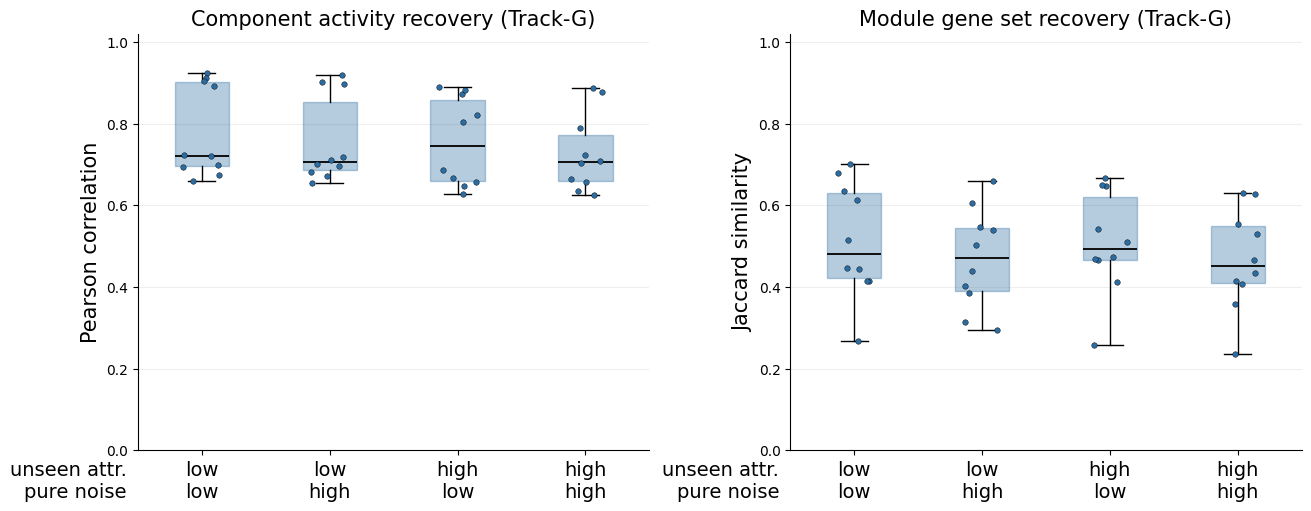

In [3]:
per_seed = res.groupby(["setting", "seed"], observed=True)[["abs_r_cell", "jaccard"]].mean()
display(per_seed.groupby("setting", observed=True).agg(["mean", "std"]).round(2).rename(index=ES.SETTING_LABEL))
ES.plot_recovery(res, path=OUT / "recovery_boxplots.pdf");

## 3. Attribute assignment (Fig. 2C)

For the component matched to each true module: the relative relatedness to the module's attribute minus that to the other attribute, $p_{true} - p_{other}$. Positive values mean that Track-G assigns the module to the correct attribute.

median  share_correct
setting                                         attribute                       
unseen attr. contribution low, pure noise low   cell type    0.77           1.00
                                                lineage      0.44           0.70
unseen attr. contribution low, pure noise high  cell type    0.78           1.00
                                                lineage      0.33           0.65
unseen attr. contribution high, pure noise low  cell type    0.76           1.00
                                                lineage      0.41           0.65
unseen attr. contribution high, pure noise high cell type    0.75           1.00
                                                lineage     -0.02           0.50

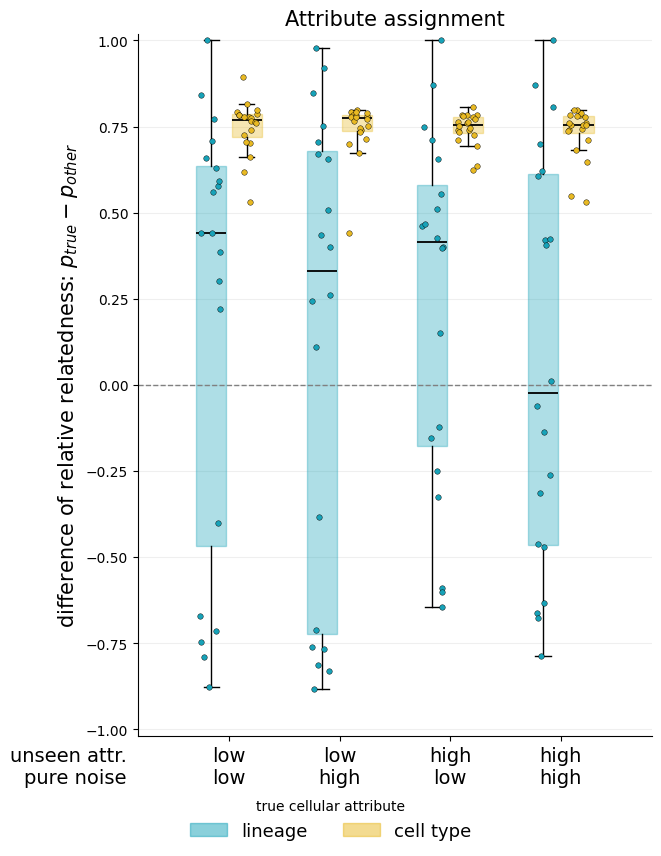

In [4]:
assign = res.groupby(["setting", "attribute"], observed=True)["p_diff"].agg(
    median="median", share_correct=lambda v: (v > 0).mean())
display(assign.round(2).rename(index=ES.SETTING_LABEL, level=0))
ES.plot_attribute_assignment(res, path=OUT / "attribute_assignment.pdf");

## 4. Correlation between the true modules and the Track-G components (Supplementary Fig. S3)

Absolute Pearson correlation between the true module activities (rows) and the cell scores of the Track-G components (columns, in the order of the matched modules; matched pairs boxed), averaged over the 10 seeds, and for seed 0 alone (columns named by the dominating attribute of the component).

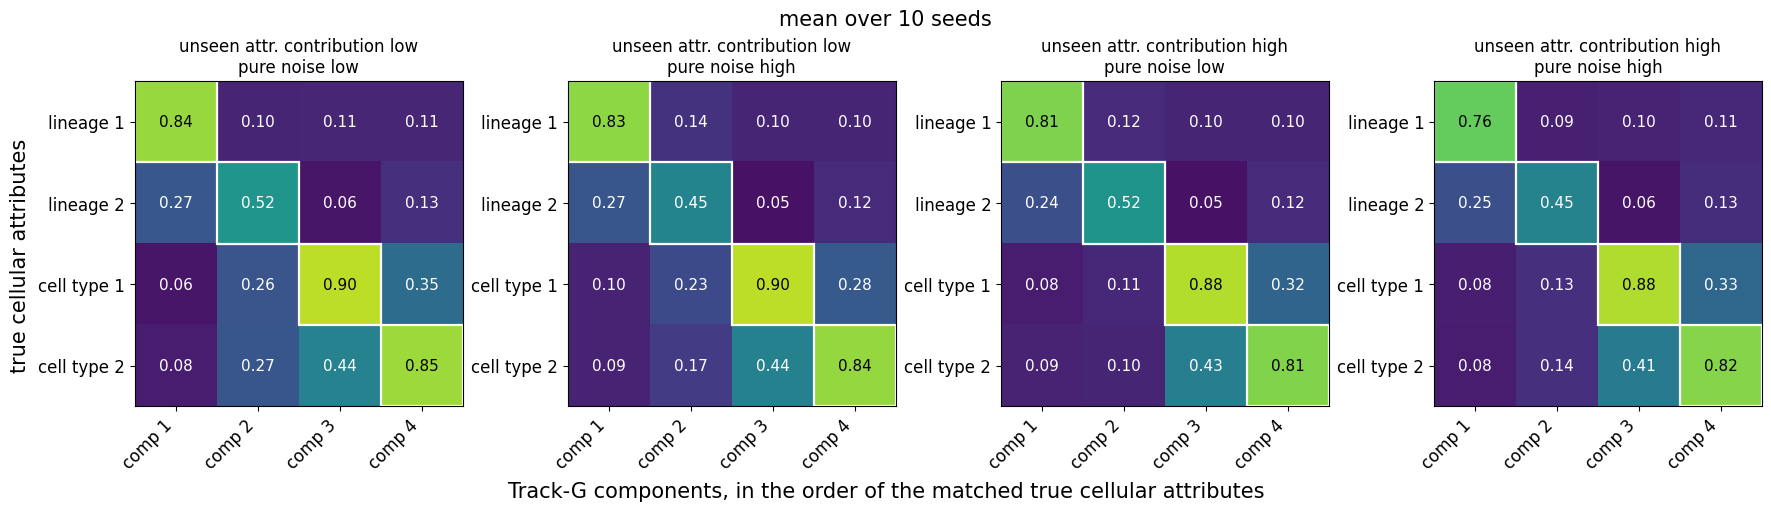

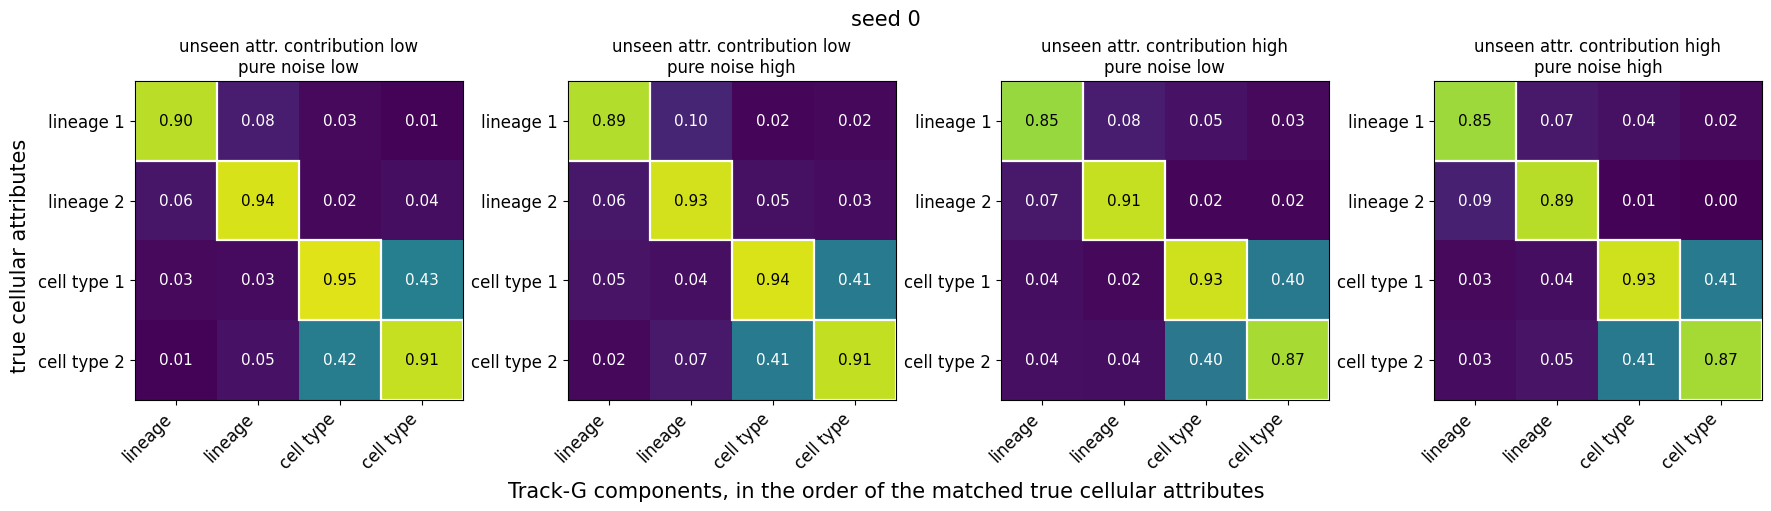

In [5]:
ES.plot_corr_heatmaps(store, seeds=ES.SEEDS, path=OUT / "mean_corr_heatmaps.pdf")
ES.plot_corr_heatmaps(store, seeds=[0], path=OUT / "seed0_corr_heatmaps.pdf");